# Decision Tree Model for Network Traffic Classification

This notebook trains **one complete model**: a **Decision Tree** classifier.

**Goal:** look at the time-based features of a network flow and predict what kind of traffic it is
(for example `CHAT`, `VOIP`, `VPN-FT`, ...). There are **14 classes** (7 normal + 7 VPN).

**Data:** ISCX VPN-nonVPN 2016, Scenario B. We use the processed train and test files that the team already made
in `data/processed/`. These files already have duplicates removed and use a group-aware 80/20 split,
so the same flow never appears in both train and test.

**Why a Decision Tree?** A decision tree learns simple *if / else* rules from the data
(for example *"if duration < 5000 and mean_flowiat > 300 then VOIP"*). It is easy to understand,
does not need feature scaling, and can learn non-linear patterns that Logistic Regression cannot.

**What this notebook does:**

1. Load the data and look at it
2. Train a simple baseline Decision Tree
3. Hyperparameter tuning with randomized search
4. Cross validation of the best model
5. Learning curve
6. Validation curves (`max_depth`, `min_samples_leaf`, `ccp_alpha`)
7. Final test on the hold-out test set
8. Confusion matrix and class report
9. Feature importance
10. Look inside the tree (tree plot and rules)
11. Run the tuned model on all four time windows
12. Compare with the team's Logistic Regression
13. Save the model

All results are saved in a separate folder: **`reports/results/decision_tree/`**

## 1. Import libraries

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import permutation_importance
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV,
    cross_validate,
    learning_curve,
    validation_curve,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

## 2. Settings and folders

Here we set the main settings in one place.

- `TIMEOUT = 15` : we use the 15 second time window for the main work (the team also used 15s as the main dataset).
- `TASK = "14class"` : 14 traffic classes.
- `SEED = 42` : fixed random seed so results are the same every time.
- `N_FOLDS = 5` : 5-fold cross validation.
- `N_ITER = 150` : number of random settings tried during tuning. A single tree trains very fast, so we can try many.

The notebook finds the project folder by itself, so it works if you run it from the `notebooks/` folder
or from the project folder. If the results folder does not exist, it is created.

In [2]:
TIMEOUT = 15
TASK = "14class"
SEED = 42
N_FOLDS = 5
N_ITER = 150
ALL_TIMEOUTS = [15, 30, 60, 120]
TARGET = "label"

FEATURES = [
    "duration", "min_fiat", "min_biat", "max_fiat", "max_biat", "mean_fiat",
    "mean_biat", "flowPktsPerSecond", "flowBytesPerSecond", "min_flowiat",
    "max_flowiat", "mean_flowiat", "std_flowiat", "min_active", "mean_active",
    "max_active", "std_active", "min_idle", "mean_idle", "max_idle", "std_idle",
]

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR = PROJECT_ROOT / "reports" / "results" / "decision_tree"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
MODEL_DIR = OUT_DIR / "model"

for folder in [FIG_DIR, TAB_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Results folder:", OUT_DIR)

Project folder: C:\Users\suner\Downloads\ml\ML-Traffic-Classification-main
Results folder: C:\Users\suner\Downloads\ml\ML-Traffic-Classification-main\reports\results\decision_tree


## 3. Load the data

We load the train and test files. Each file has:

- 21 feature columns
- `label` : the traffic class (what we want to predict)
- `group_id` : rows with exactly the same features share the same id
- `conflict_flag` : 1 if the same features appear with more than one label

We keep `group_id` because we use it in cross validation, so the same flow does not end up in both the
training fold and the validation fold.

In [3]:
def load_split(timeout, task=TASK):
    train = pd.read_csv(DATA_DIR / f"{task}_{timeout}s_train.csv")
    test = pd.read_csv(DATA_DIR / f"{task}_{timeout}s_test.csv")
    return train, test

train_df, test_df = load_split(TIMEOUT)

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
groups_train = train_df["group_id"]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

CLASSES = sorted(y_train.unique())

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("Number of classes:", len(CLASSES))
print("Missing values in train:", int(X_train.isnull().sum().sum()))
print("Missing values in test :", int(X_test.isnull().sum().sum()))
print("Conflict rows in train:", int(train_df["conflict_flag"].sum()))
print("Conflict rows in test :", int(test_df["conflict_flag"].sum()))
train_df.head()

Train shape: (14459, 21)
Test shape : (3615, 21)
Number of classes: 14
Missing values in train: 0
Missing values in test : 0
Conflict rows in train: 82
Conflict rows in test : 18


,duration,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,label,group_id,conflict_flag
0,9368711.0,1564818.0,1549373.0,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4.0,1523088.0,97590.739583,267600.198443,1871488.0,1.983656e+06,2195089.0,1.832197e+05,1234883.0,1420565.0,1523088.0,161096.539275,CHAT,0,0
1,7340238.0,1567554.0,1527893.0,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4.0,1517774.0,87383.785714,221462.862028,1491627.0,3.572433e+06,5653239.0,2.942704e+06,1131498.0,1324636.0,1517774.0,273138.379008,CHAT,1,0
2,4644225.0,1270547.0,1079974.0,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15.0,1079974.0,89312.019231,217475.425246,1758922.0,1.758922e+06,1758922.0,0.000000e+00,1079974.0,1079974.0,1079974.0,0.000000,CHAT,2,0
3,4978735.0,2492050.0,2457286.0,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8.0,2441990.0,127659.871795,436959.716436,1710925.0,2.382905e+06,3054885.0,9.503232e+05,1346073.0,1894031.5,2441990.0,774930.342317,CHAT,3,0
4,11838189.0,3094089.0,3093543.0,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10.0,3042717.0,133013.359551,436129.639296,1747431.0,2.400446e+06,3240696.0,6.232744e+05,1394455.0,1983227.0,3042717.0,725987.829075,CHAT,4,0


## 4. Look at the class balance

Some classes have many rows (like `BROWSING` and `VOIP`) and some have very few (like `MAIL`).
This is called **class imbalance**. Because of this, plain accuracy can look good even if small classes
are predicted badly. So our main score is **macro F1**, which gives every class the same weight.

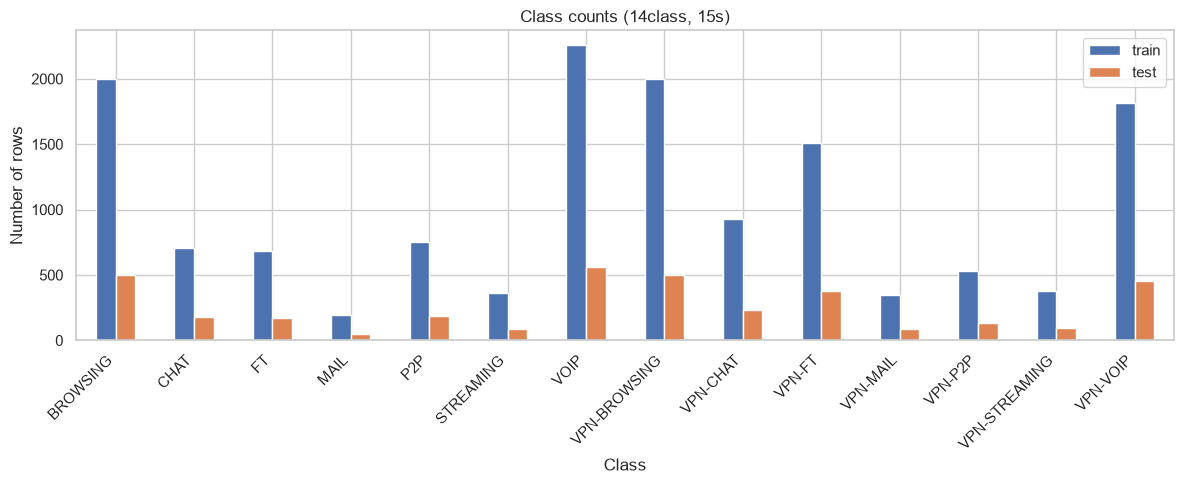

,train,test,train_%
label,,,
BROWSING,2000,500,13.83
CHAT,710,177,4.91
FT,685,172,4.74
MAIL,191,47,1.32
P2P,753,188,5.21
STREAMING,360,90,2.49
VOIP,2257,564,15.61
VPN-BROWSING,2000,500,13.83
VPN-CHAT,926,232,6.40


In [4]:
class_counts = pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).loc[CLASSES]
class_counts["train_%"] = (100 * class_counts["train"] / class_counts["train"].sum()).round(2)
class_counts.to_csv(TAB_DIR / "class_counts.csv")

fig, ax = plt.subplots(figsize=(12, 5))
class_counts[["train", "test"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title(f"Class counts ({TASK}, {TIMEOUT}s)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_counts.png", dpi=200, bbox_inches="tight")
plt.show()

class_counts

## 5. Quick look at the features

A Decision Tree does not need scaled features, because it only splits values with simple rules like
`duration < 5000`. So we do **not** use a scaler here. Below is a short summary of each feature.
Some features have `-1` values. The team checked these and kept them, so we keep them too.

In [5]:
feature_summary = X_train.describe().T
feature_summary.to_csv(TAB_DIR / "feature_summary.csv")
feature_summary

,count,mean,std,min,25%,50%,75%,max
duration,14459.0,1.015701e+07,1.428622e+07,0.0,612652.500000,1.182602e+07,1.496303e+07,6.014050e+08
min_fiat,14459.0,3.467052e+06,1.121891e+07,-1.0,27975.000000,3.237810e+05,4.438964e+06,3.035957e+08
min_biat,14459.0,2.912495e+06,8.946455e+06,-1.0,25250.000000,3.522600e+05,4.406240e+06,6.001097e+08
max_fiat,14459.0,1.036727e+06,3.298948e+06,0.0,17615.478000,6.853200e+04,5.631879e+05,1.520000e+08
max_biat,14459.0,9.369807e+05,2.489874e+06,0.0,10660.900000,4.596370e+04,5.142301e+05,4.000000e+07
mean_fiat,14459.0,8.905535e+05,4.629786e+06,0.0,585.386719,1.336213e+04,6.642229e+05,2.150000e+08
mean_biat,14459.0,6.247219e+05,2.465725e+06,0.0,573.464300,1.481586e+04,5.984849e+05,9.800000e+07
flowPktsPerSecond,14459.0,1.378837e+03,1.145914e+04,0.0,3.230075,1.237624e+01,1.006952e+02,6.666667e+05
flowBytesPerSecond,14459.0,4.170514e+05,8.754578e+06,0.0,467.641391,2.866629e+03,1.352865e+04,6.170000e+08
min_flowiat,14459.0,4.264978e+04,4.499808e+05,-1247.0,4.000000,1.800000e+01,1.940000e+02,1.891990e+07


## 6. Evaluation helper

This small function gives all the scores we care about in one table:

- **Accuracy** : how many predictions are correct
- **Balanced accuracy** : average recall of each class
- **Macro precision / recall / F1** : average over classes, every class has the same weight
- **Weighted F1** : average over classes, weighted by class size
- **MCC** : Matthews correlation coefficient, a strong single score for multi-class problems

In [6]:
def get_scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }

cv_splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

SCORING = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
}

## 7. Baseline Decision Tree

First we train a Decision Tree with the **default settings**. This gives us a starting point.
Later we will check if tuning makes it better.

We test it with 5-fold cross validation on the **training data only**. The test set is kept aside until the end.

In [7]:
baseline_model = DecisionTreeClassifier(random_state=SEED)

start = time.time()
baseline_cv = cross_validate(
    baseline_model, X_train, y_train,
    groups=groups_train, cv=cv_splitter,
    scoring=SCORING, return_train_score=True, n_jobs=-1,
)
print(f"Time: {time.time() - start:.1f} s")

baseline_cv_table = pd.DataFrame({
    metric: {
        "train_mean": baseline_cv[f"train_{metric}"].mean(),
        "val_mean": baseline_cv[f"test_{metric}"].mean(),
        "val_std": baseline_cv[f"test_{metric}"].std(),
    }
    for metric in SCORING
}).T
baseline_cv_table.to_csv(TAB_DIR / "baseline_cv_scores.csv")

baseline_size = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
print("Baseline tree depth :", baseline_size.get_depth())
print("Baseline tree leaves:", baseline_size.get_n_leaves())
baseline_cv_table.round(4)

Time: 21.2 s


Baseline tree depth : 29
Baseline tree leaves: 2259


,train_mean,val_mean,val_std
accuracy,0.9966,0.7736,0.0074
balanced_accuracy,0.9924,0.7457,0.0125
macro_f1,0.9922,0.7429,0.0112
weighted_f1,0.9966,0.7739,0.0068


The default tree grows until every leaf is pure. So the train score is almost 1.0, but the validation score
is much lower. The tree is very deep and has thousands of leaves. This means the default tree
**overfits**: it remembers the training data instead of learning general rules. Tuning will limit
the tree so it generalizes better.

## 8. Hyperparameter tuning

We use **RandomizedSearchCV**. It tries `N_ITER` random combinations of settings and checks each one
with 5-fold group-aware cross validation. The best one is chosen by **macro F1**.

Settings we search:

| Setting | What it means |
|---|---|
| `criterion` | how the tree measures a good split (`gini`, `entropy`, `log_loss`) |
| `splitter` | `best` = try all split points, `random` = try random split points |
| `max_depth` | how deep the tree can grow |
| `min_samples_split` | minimum rows needed to split a node |
| `min_samples_leaf` | minimum rows in a leaf |
| `max_features` | how many features each split can look at |
| `class_weight` | give more weight to small classes or not |
| `ccp_alpha` | pruning strength: bigger value = smaller, simpler tree |

In [8]:
param_space = {
    "criterion": ["gini", "entropy", "log_loss"],
    "splitter": ["best", "random"],
    "max_depth": [None, 5, 8, 10, 12, 15, 18, 20, 25, 30],
    "min_samples_split": [2, 5, 10, 20, 40],
    "min_samples_leaf": [1, 2, 4, 6, 8, 12, 16, 20],
    "max_features": [None, "sqrt", "log2", 0.5, 0.7],
    "class_weight": [None, "balanced"],
    "ccp_alpha": [0.0, 0.00005, 0.0001, 0.0002, 0.0005, 0.001],
}

search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=SEED),
    param_distributions=param_space,
    n_iter=N_ITER,
    scoring=SCORING,
    refit="macro_f1",
    cv=cv_splitter,
    random_state=SEED,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

start = time.time()
search.fit(X_train, y_train, groups=groups_train)
print(f"Tuning time: {(time.time() - start) / 60:.1f} min")

best_params = search.best_params_
print("Best macro F1 (CV):", round(search.best_score_, 4))
print("Best settings:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

def to_json_value(v):
    return v.item() if isinstance(v, np.generic) else v

with open(OUT_DIR / "best_params.json", "w") as f:
    json.dump({k: to_json_value(v) for k, v in best_params.items()}, f, indent=2)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


Tuning time: 2.4 min
Best macro F1 (CV): 0.7486
Best settings:
  splitter: best
  min_samples_split: 2
  min_samples_leaf: 2
  max_features: 0.5
  max_depth: 25
  criterion: gini
  class_weight: None
  ccp_alpha: 0.0002


### 8.1 All tuning results

The table shows the top settings that were tried, sorted from best to worst by validation macro F1.
The full list is saved as `tables/tuning_results.csv`.

In [9]:
tuning_results = pd.DataFrame(search.cv_results_)
keep_cols = [c for c in tuning_results.columns if c.startswith("param_")] + [
    "mean_train_macro_f1", "mean_test_macro_f1", "std_test_macro_f1",
    "mean_test_accuracy", "mean_test_balanced_accuracy", "rank_test_macro_f1",
]
tuning_results = tuning_results[keep_cols].sort_values("rank_test_macro_f1")
tuning_results.to_csv(TAB_DIR / "tuning_results.csv", index=False)
tuning_results.head(10).round(4)

,param_splitter,param_min_samples_split,param_min_samples_leaf,param_max_features,param_max_depth,param_criterion,param_class_weight,param_ccp_alpha,mean_train_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_test_balanced_accuracy,rank_test_macro_f1
121,best,2,2,0.5,25,gini,NaN,0.0002,0.8630,0.7486,0.0082,0.7802,0.7480,1
51,best,2,1,0.7,30,log_loss,NaN,0.0000,0.9922,0.7464,0.0064,0.7821,0.7488,2
97,best,5,4,None,25,log_loss,NaN,0.0000,0.8784,0.7417,0.0084,0.7771,0.7391,3
58,best,10,2,0.7,25,log_loss,NaN,0.0000,0.8822,0.7376,0.0067,0.7718,0.7371,4
71,best,10,2,None,25,gini,NaN,0.0001,0.8753,0.7329,0.0124,0.7680,0.7330,5
9,best,10,1,0.7,15,entropy,NaN,0.0010,0.8154,0.7298,0.0098,0.7653,0.7271,6
94,best,20,2,0.5,None,entropy,NaN,0.0001,0.8290,0.7297,0.0042,0.7664,0.7249,7
1,best,5,2,0.7,30,log_loss,NaN,0.0010,0.8122,0.7284,0.0047,0.7669,0.7235,8
2,best,10,2,sqrt,30,entropy,NaN,0.0005,0.8345,0.7179,0.0086,0.7561,0.7177,9
38,best,20,1,None,12,entropy,balanced,0.0000,0.8099,0.7136,0.0101,0.7504,0.7426,10


### 8.2 Tuning results as a chart

Each dot is one setting. A big gap between the train and validation dot means that setting overfits.

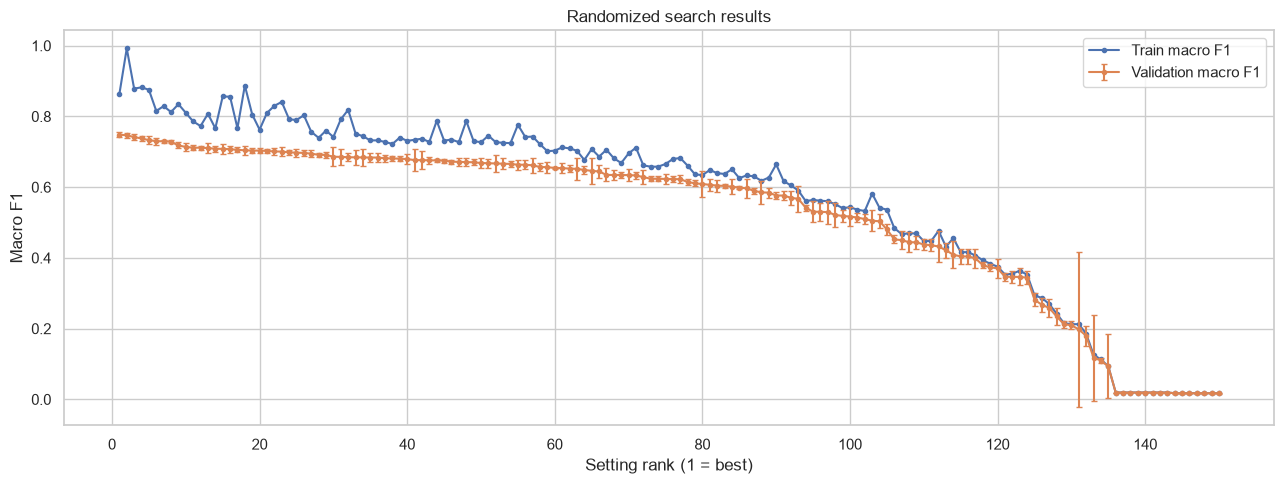

In [10]:
plot_df = tuning_results.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(plot_df.index + 1, plot_df["mean_train_macro_f1"], ".-", label="Train macro F1")
ax.errorbar(plot_df.index + 1, plot_df["mean_test_macro_f1"], yerr=plot_df["std_test_macro_f1"],
            fmt=".-", capsize=2, label="Validation macro F1")
ax.set_xlabel("Setting rank (1 = best)")
ax.set_ylabel("Macro F1")
ax.set_title("Randomized search results")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_results.png", dpi=200, bbox_inches="tight")
plt.show()

### 8.3 Which settings matter the most?

For the most important settings we show the average validation macro F1 for each value.
This helps to explain *why* the best setting was chosen.

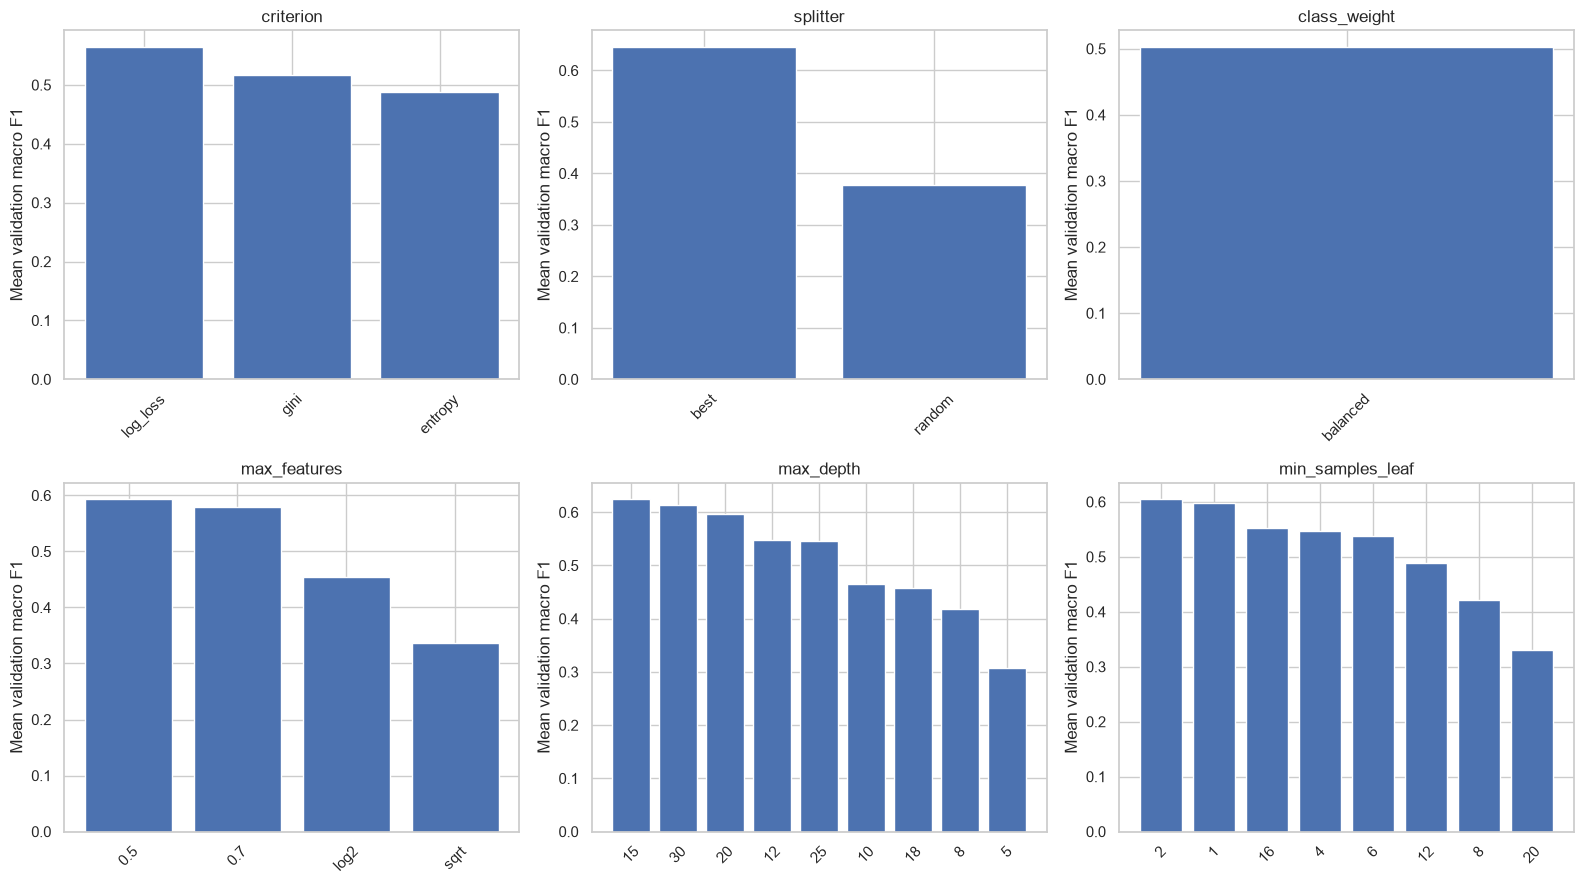

In [11]:
setting_names = ["criterion", "splitter", "class_weight", "max_features", "max_depth", "min_samples_leaf"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.ravel(), setting_names):
    col = f"param_{name}"
    summary = (
        tuning_results.assign(value=tuning_results[col].astype(str))
        .groupby("value")["mean_test_macro_f1"].mean()
        .sort_values(ascending=False)
    )
    ax.bar(summary.index, summary.values, color="#4C72B0")
    ax.set_title(name)
    ax.set_ylabel("Mean validation macro F1")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_setting_effects.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Cross validation of the best model

Now we take the best settings and run 5-fold cross validation again, this time keeping the score of
**each fold**. This shows how stable the model is. A small standard deviation means the model gives
similar results on different parts of the data. Single decision trees can be unstable, so this check is important.

In [12]:
best_model = DecisionTreeClassifier(**best_params, random_state=SEED)

tuned_cv = cross_validate(
    best_model, X_train, y_train,
    groups=groups_train, cv=cv_splitter,
    scoring=SCORING, return_train_score=True, n_jobs=-1,
)

fold_table = pd.DataFrame({
    "fold": range(1, N_FOLDS + 1),
    **{f"train_{m}": tuned_cv[f"train_{m}"] for m in SCORING},
    **{f"val_{m}": tuned_cv[f"test_{m}"] for m in SCORING},
})
fold_table.to_csv(TAB_DIR / "tuned_cv_folds.csv", index=False)

tuned_cv_table = pd.DataFrame({
    metric: {
        "train_mean": tuned_cv[f"train_{metric}"].mean(),
        "val_mean": tuned_cv[f"test_{metric}"].mean(),
        "val_std": tuned_cv[f"test_{metric}"].std(),
    }
    for metric in SCORING
}).T
tuned_cv_table.to_csv(TAB_DIR / "tuned_cv_scores.csv")

display(fold_table.round(4))
tuned_cv_table.round(4)

,fold,train_accuracy,train_balanced_accuracy,train_macro_f1,train_weighted_f1,val_accuracy,val_balanced_accuracy,val_macro_f1,val_weighted_f1
0,1,0.8906,0.8587,0.8605,0.8903,0.7929,0.7590,0.7593,0.7925
1,2,0.8912,0.8576,0.8630,0.8908,0.7711,0.7400,0.7454,0.7704
2,3,0.8886,0.8575,0.8611,0.8882,0.7835,0.7559,0.7565,0.7834
3,4,0.8930,0.8645,0.8659,0.8928,0.7766,0.7352,0.7373,0.7768
4,5,0.8916,0.8627,0.8647,0.8912,0.7769,0.7502,0.7444,0.7772


,train_mean,val_mean,val_std
accuracy,0.8910,0.7802,0.0075
balanced_accuracy,0.8602,0.7480,0.0091
macro_f1,0.8630,0.7486,0.0082
weighted_f1,0.8906,0.7800,0.0075


### 9.1 Score of each fold

This chart shows the validation score of each fold. If the bars are about the same height, the model is stable.

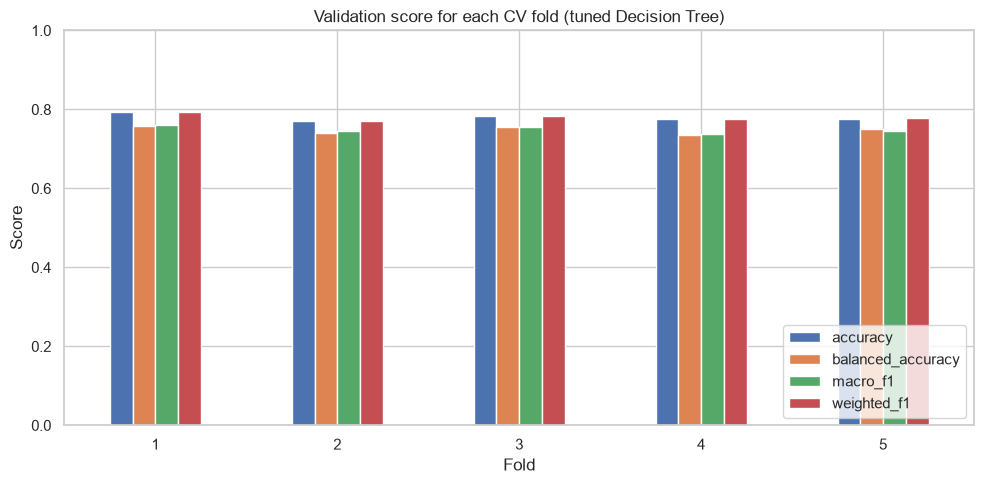

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
fold_plot = fold_table.set_index("fold")[[f"val_{m}" for m in SCORING]]
fold_plot.columns = list(SCORING)
fold_plot.plot(kind="bar", ax=ax)
ax.set_title("Validation score for each CV fold (tuned Decision Tree)")
ax.set_xlabel("Fold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "cv_folds.png", dpi=200, bbox_inches="tight")
plt.show()

### 9.2 Baseline vs tuned (cross validation)

Here we compare the default tree and the tuned tree using the cross validation scores.

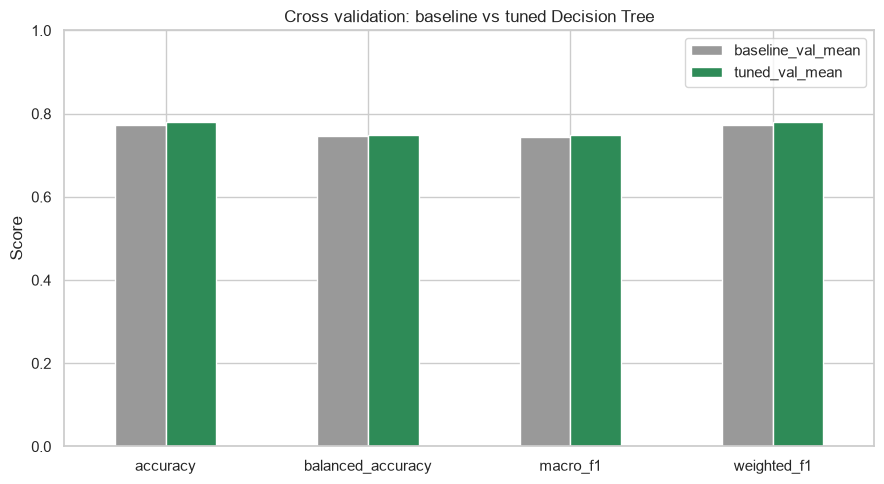

,baseline_val_mean,tuned_val_mean,baseline_train_mean,tuned_train_mean,val_change,baseline_gap,tuned_gap
accuracy,0.7736,0.7802,0.9966,0.8910,0.0066,0.2230,0.1108
balanced_accuracy,0.7457,0.7480,0.9924,0.8602,0.0024,0.2468,0.1121
macro_f1,0.7429,0.7486,0.9922,0.8630,0.0056,0.2493,0.1145
weighted_f1,0.7739,0.7800,0.9966,0.8906,0.0061,0.2227,0.1106


In [14]:
cv_compare = pd.DataFrame({
    "baseline_val_mean": baseline_cv_table["val_mean"],
    "tuned_val_mean": tuned_cv_table["val_mean"],
    "baseline_train_mean": baseline_cv_table["train_mean"],
    "tuned_train_mean": tuned_cv_table["train_mean"],
})
cv_compare["val_change"] = cv_compare["tuned_val_mean"] - cv_compare["baseline_val_mean"]
cv_compare["baseline_gap"] = cv_compare["baseline_train_mean"] - cv_compare["baseline_val_mean"]
cv_compare["tuned_gap"] = cv_compare["tuned_train_mean"] - cv_compare["tuned_val_mean"]
cv_compare.to_csv(TAB_DIR / "baseline_vs_tuned_cv.csv")

fig, ax = plt.subplots(figsize=(9, 5))
cv_compare[["baseline_val_mean", "tuned_val_mean"]].plot(kind="bar", ax=ax, color=["#999999", "#2E8B57"])
ax.set_title("Cross validation: baseline vs tuned Decision Tree")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_vs_tuned_cv.png", dpi=200, bbox_inches="tight")
plt.show()

cv_compare.round(4)

## 10. Learning curve

A learning curve trains the model on bigger and bigger parts of the training data and shows the
train score and the validation score each time.

How to read it:

- If both lines are low and close → the model is too simple (**underfitting**).
- If the train line is high and the validation line is much lower → the model **overfits**.
- If the validation line is still going up at the end → **more data would help**.

We draw it for both the **baseline** tree and the **tuned** tree so we can see how tuning closes the gap.

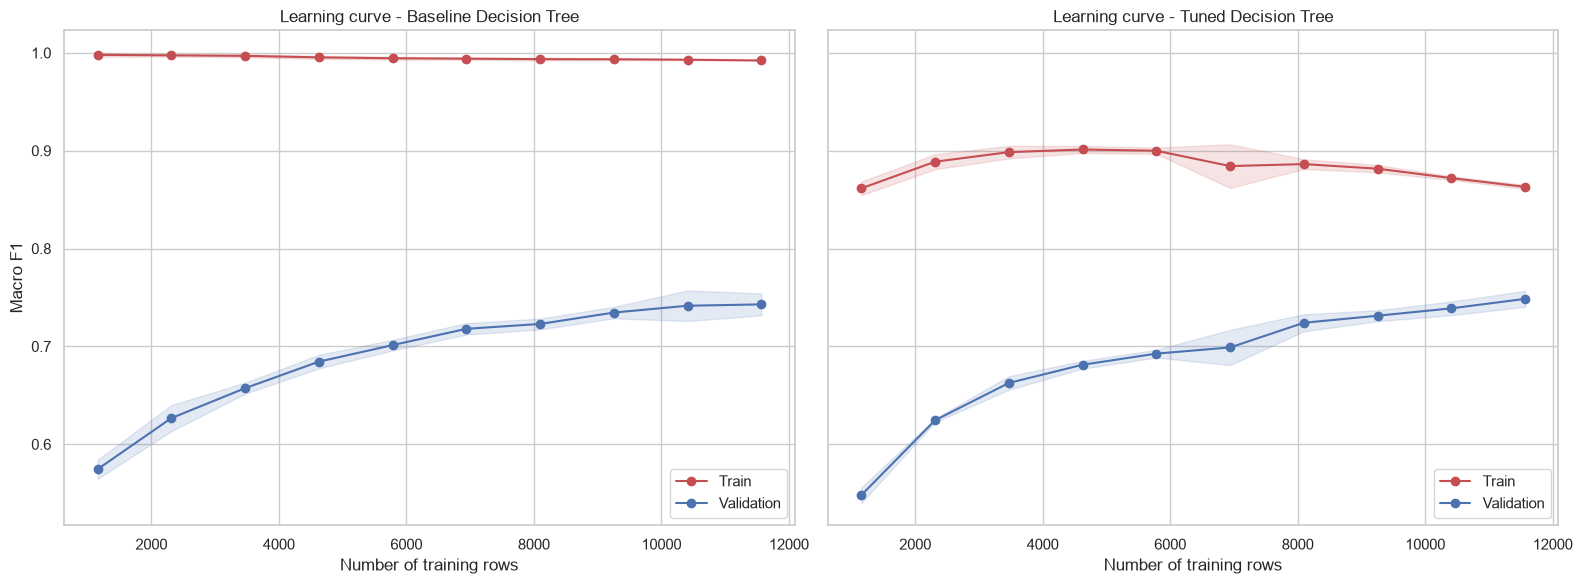

,train_size,train_mean,train_std,val_mean,val_std
0,1156,0.8616,0.0071,0.5480,0.0079
1,2313,0.8887,0.0076,0.6245,0.0019
2,3470,0.8985,0.0064,0.6626,0.0069
3,4626,0.9012,0.0036,0.6812,0.0039
4,5783,0.8999,0.0032,0.6926,0.0040
5,6940,0.8843,0.0223,0.6989,0.0180
6,8096,0.8863,0.0050,0.7241,0.0087
7,9253,0.8816,0.0037,0.7313,0.0056
8,10410,0.8720,0.0020,0.7389,0.0070
9,11567,0.8630,0.0020,0.7486,0.0082


In [15]:
def make_learning_curve(model):
    sizes, tr, va = learning_curve(
        model, X_train, y_train,
        groups=groups_train, cv=cv_splitter,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring="f1_macro", n_jobs=-1, shuffle=True, random_state=SEED,
    )
    return pd.DataFrame({
        "train_size": sizes,
        "train_mean": tr.mean(axis=1), "train_std": tr.std(axis=1),
        "val_mean": va.mean(axis=1), "val_std": va.std(axis=1),
    })

lc_tuned = make_learning_curve(best_model)
lc_base = make_learning_curve(DecisionTreeClassifier(random_state=SEED))
lc_tuned.to_csv(TAB_DIR / "learning_curve_tuned.csv", index=False)
lc_base.to_csv(TAB_DIR / "learning_curve_baseline.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, table, title in [(axes[0], lc_base, "Baseline Decision Tree"), (axes[1], lc_tuned, "Tuned Decision Tree")]:
    ax.plot(table["train_size"], table["train_mean"], "o-", color="#C44E52", label="Train")
    ax.fill_between(table["train_size"], table["train_mean"] - table["train_std"],
                    table["train_mean"] + table["train_std"], alpha=0.15, color="#C44E52")
    ax.plot(table["train_size"], table["val_mean"], "o-", color="#4C72B0", label="Validation")
    ax.fill_between(table["train_size"], table["val_mean"] - table["val_std"],
                    table["val_mean"] + table["val_std"], alpha=0.15, color="#4C72B0")
    ax.set_xlabel("Number of training rows")
    ax.set_title(f"Learning curve - {title}")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Macro F1")
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

lc_tuned.round(4)

## 11. Validation curves

A validation curve changes **one** setting and keeps the others at their best values.
It shows clearly where the model starts to overfit (train score goes up, validation score stops improving
or goes down) and where it underfits (both scores are low).

We check three settings that control the **size of the tree**:

- `max_depth` : how deep the tree can grow
- `min_samples_leaf` : minimum rows in each leaf
- `ccp_alpha` : pruning strength

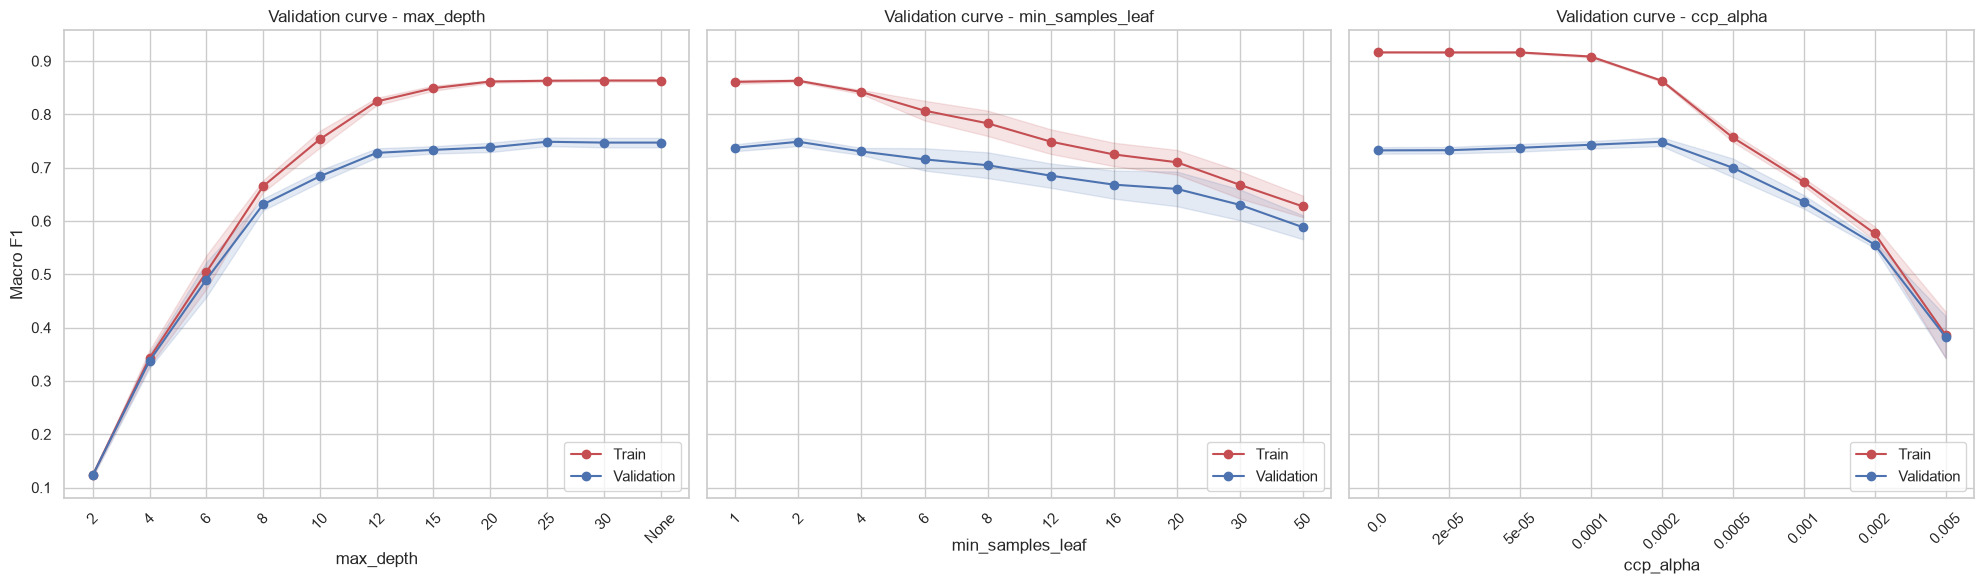

,max_depth,train_mean,train_std,val_mean,val_std
0,2,0.1233,0.0009,0.1233,0.0037
1,4,0.3432,0.0146,0.3377,0.0135
2,6,0.5039,0.0314,0.4902,0.0325
3,8,0.6651,0.0112,0.6310,0.0110
4,10,0.7533,0.0158,0.6839,0.0112
5,12,0.8241,0.0069,0.7277,0.0087
6,15,0.8491,0.0048,0.7334,0.0068
7,20,0.8615,0.0024,0.7380,0.0088
8,25,0.8630,0.0021,0.7486,0.0082
9,30,0.8634,0.0020,0.7470,0.0089


In [16]:
def make_validation_curve(param_name, values):
    params = {k: v for k, v in best_params.items() if k != param_name}
    tr, va = validation_curve(
        DecisionTreeClassifier(**params, random_state=SEED),
        X_train, y_train, groups=groups_train,
        param_name=param_name, param_range=values,
        cv=cv_splitter, scoring="f1_macro", n_jobs=-1,
    )
    return pd.DataFrame({
        param_name: [str(v) for v in values],
        "train_mean": tr.mean(axis=1), "train_std": tr.std(axis=1),
        "val_mean": va.mean(axis=1), "val_std": va.std(axis=1),
    })

curves = {
    "max_depth": make_validation_curve("max_depth", [2, 4, 6, 8, 10, 12, 15, 20, 25, 30, None]),
    "min_samples_leaf": make_validation_curve("min_samples_leaf", [1, 2, 4, 6, 8, 12, 16, 20, 30, 50]),
    "ccp_alpha": make_validation_curve("ccp_alpha", [0.0, 0.00002, 0.00005, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005]),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
for ax, (name, table) in zip(axes, curves.items()):
    table.to_csv(TAB_DIR / f"validation_curve_{name}.csv", index=False)
    x = np.arange(len(table))
    ax.plot(x, table["train_mean"], "o-", color="#C44E52", label="Train")
    ax.fill_between(x, table["train_mean"] - table["train_std"],
                    table["train_mean"] + table["train_std"], alpha=0.15, color="#C44E52")
    ax.plot(x, table["val_mean"], "o-", color="#4C72B0", label="Validation")
    ax.fill_between(x, table["val_mean"] - table["val_std"],
                    table["val_mean"] + table["val_std"], alpha=0.15, color="#4C72B0")
    ax.set_xticks(x)
    ax.set_xticklabels(table[name], rotation=45)
    ax.set_xlabel(name)
    ax.set_title(f"Validation curve - {name}")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Macro F1")
plt.tight_layout()
plt.savefig(FIG_DIR / "validation_curves.png", dpi=200, bbox_inches="tight")
plt.show()

curves["max_depth"].round(4)

## 12. Train the final model and test it

Now we train the tuned Decision Tree on the **full training set** and test it **once** on the hold-out
test set. The test set was never used for tuning, so this is a fair check of how the model works on new data.

In [17]:
final_model = DecisionTreeClassifier(**best_params, random_state=SEED)

start = time.time()
final_model.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.2f} s")
print("Tuned tree depth :", final_model.get_depth())
print("Tuned tree leaves:", final_model.get_n_leaves())

y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)

baseline_final = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
y_test_pred_base = baseline_final.predict(X_test)

test_scores = pd.DataFrame({
    "tuned_train": get_scores(y_train, y_train_pred),
    "tuned_test": get_scores(y_test, y_test_pred),
    "baseline_test": get_scores(y_test, y_test_pred_base),
})
test_scores.loc["tree_depth"] = [final_model.get_depth(), final_model.get_depth(), baseline_final.get_depth()]
test_scores.loc["tree_leaves"] = [final_model.get_n_leaves(), final_model.get_n_leaves(), baseline_final.get_n_leaves()]
test_scores.to_csv(TAB_DIR / "test_scores.csv")
test_scores.round(4)

Training time: 0.15 s
Tuned tree depth : 22
Tuned tree leaves: 585


,tuned_train,tuned_test,baseline_test
accuracy,0.8702,0.7776,0.7928
balanced_accuracy,0.8418,0.7266,0.7541
macro_precision,0.8448,0.7321,0.7551
macro_recall,0.8418,0.7266,0.7541
macro_f1,0.8426,0.7272,0.7538
weighted_f1,0.8702,0.7780,0.7928
mcc,0.8551,0.7517,0.7689
tree_depth,22.0000,22.0000,29.0000
tree_leaves,585.0000,585.0000,2259.0000


## 13. Class by class report

This shows precision, recall and F1 for **each class** on the test set.

- **Precision** : when the model says "class X", how often it is right
- **Recall** : of all real "class X" rows, how many the model found
- **Support** : number of test rows in that class

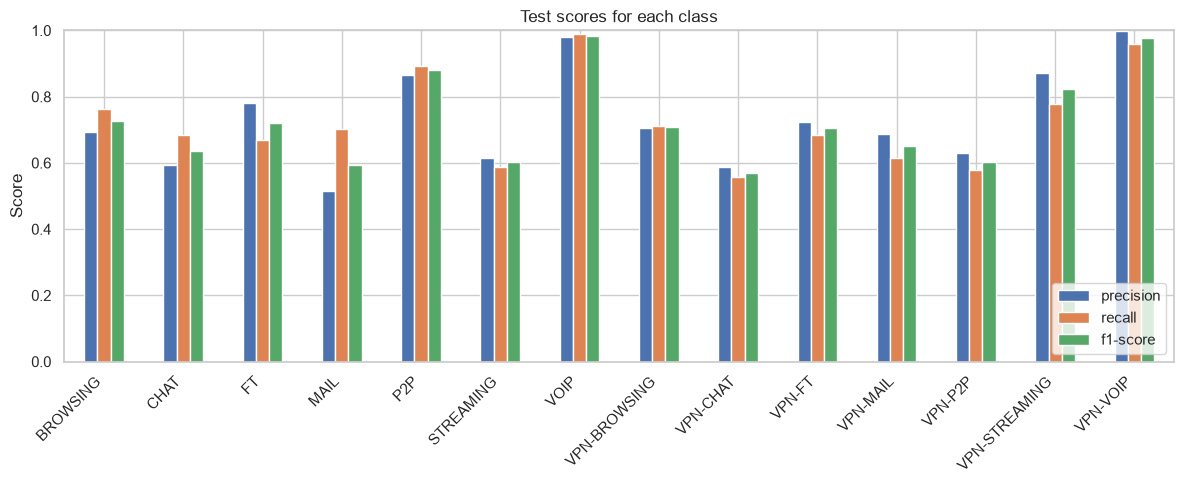

,precision,recall,f1-score,support
BROWSING,0.694,0.762,0.726,500.000
CHAT,0.593,0.684,0.635,177.000
FT,0.782,0.669,0.721,172.000
MAIL,0.516,0.702,0.595,47.000
P2P,0.866,0.894,0.880,188.000
STREAMING,0.616,0.589,0.602,90.000
VOIP,0.979,0.989,0.984,564.000
VPN-BROWSING,0.705,0.712,0.708,500.000
VPN-CHAT,0.586,0.556,0.571,232.000
VPN-FT,0.725,0.684,0.704,377.000


In [18]:
report = classification_report(y_test, y_test_pred, labels=CLASSES, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(TAB_DIR / "classification_report.csv")

per_class = report_df.loc[CLASSES, ["precision", "recall", "f1-score"]]
fig, ax = plt.subplots(figsize=(12, 5))
per_class.plot(kind="bar", ax=ax)
ax.set_title("Test scores for each class")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "per_class_scores.png", dpi=200, bbox_inches="tight")
plt.show()

report_df.round(3)

## 14. Confusion matrix

Rows are the **real** class and columns are the **predicted** class. The numbers on the diagonal are correct
predictions. Numbers outside the diagonal show which classes get mixed up.

We show two versions:

- **Counts** : number of rows
- **Normalized** : each row divided by its total, so each row shows the recall of that class

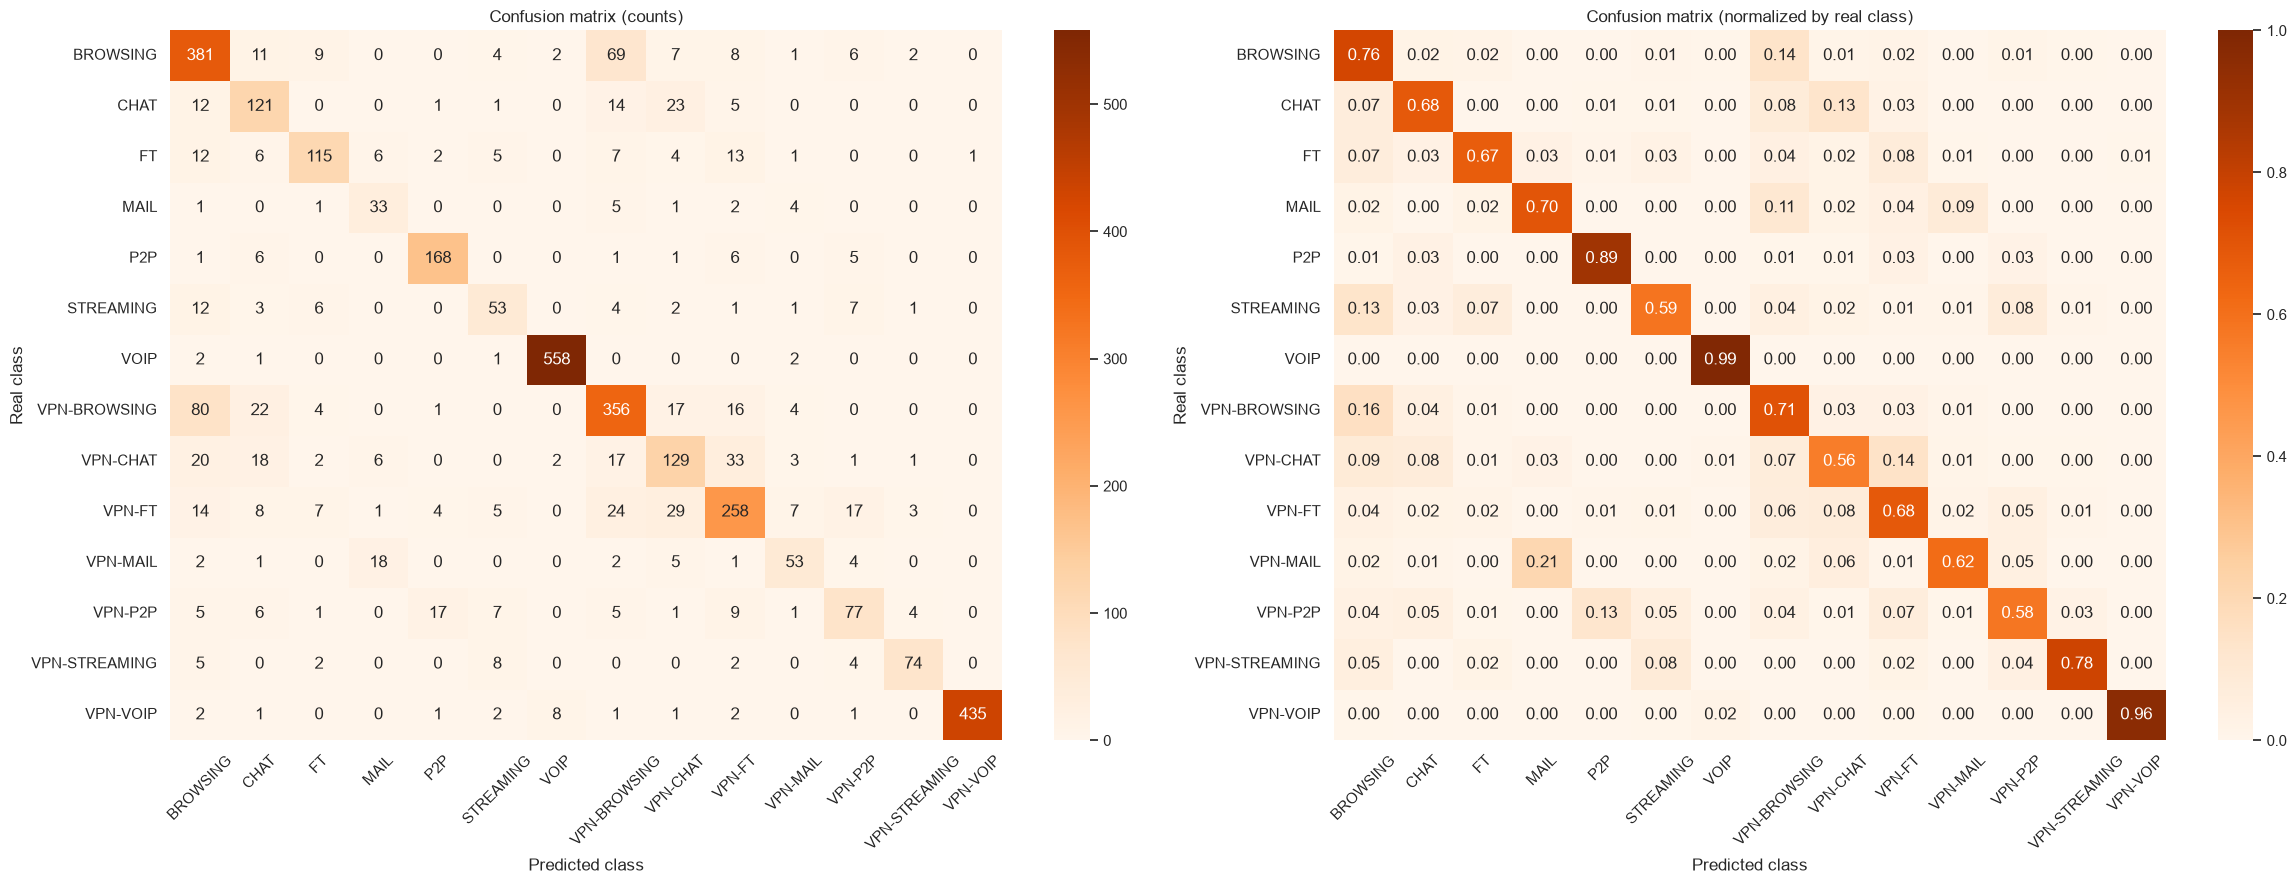

In [19]:
cm = confusion_matrix(y_test, y_test_pred, labels=CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(TAB_DIR / "confusion_matrix.csv")

fig, axes = plt.subplots(1, 2, figsize=(24, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Confusion matrix (normalized by real class)")
for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Real class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

### 14.1 Most common mistakes

This table lists the pairs of classes that the model mixes up the most.

In [20]:
mistakes = (
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
    .stack()
    .rename_axis(["real", "predicted"])
    .reset_index(name="count")
)
mistakes = mistakes[mistakes["real"] != mistakes["predicted"]].sort_values("count", ascending=False)
mistakes["share_of_real_class_%"] = (
    100 * mistakes["count"] / mistakes["real"].map(y_test.value_counts())
).round(1)
mistakes.to_csv(TAB_DIR / "top_mistakes.csv", index=False)
mistakes.head(10)

,real,predicted,count,share_of_real_class_%
98,VPN-BROWSING,BROWSING,80,16.0
7,BROWSING,VPN-BROWSING,69,13.8
121,VPN-CHAT,VPN-FT,33,14.2
134,VPN-FT,VPN-CHAT,29,7.7
133,VPN-FT,VPN-BROWSING,24,6.4
22,CHAT,VPN-CHAT,23,13.0
99,VPN-BROWSING,CHAT,22,4.4
112,VPN-CHAT,BROWSING,20,8.6
143,VPN-MAIL,MAIL,18,20.9
113,VPN-CHAT,CHAT,18,7.8


## 15. Feature importance

We look at which features help the model the most, in two ways:

- **Impurity importance** : built into the Decision Tree. It shows how much each feature helps to split the data cleanly.
- **Permutation importance** : we shuffle one feature in the test set and see how much macro F1 drops.
  A bigger drop means the feature is more important. This is the more trusted method.

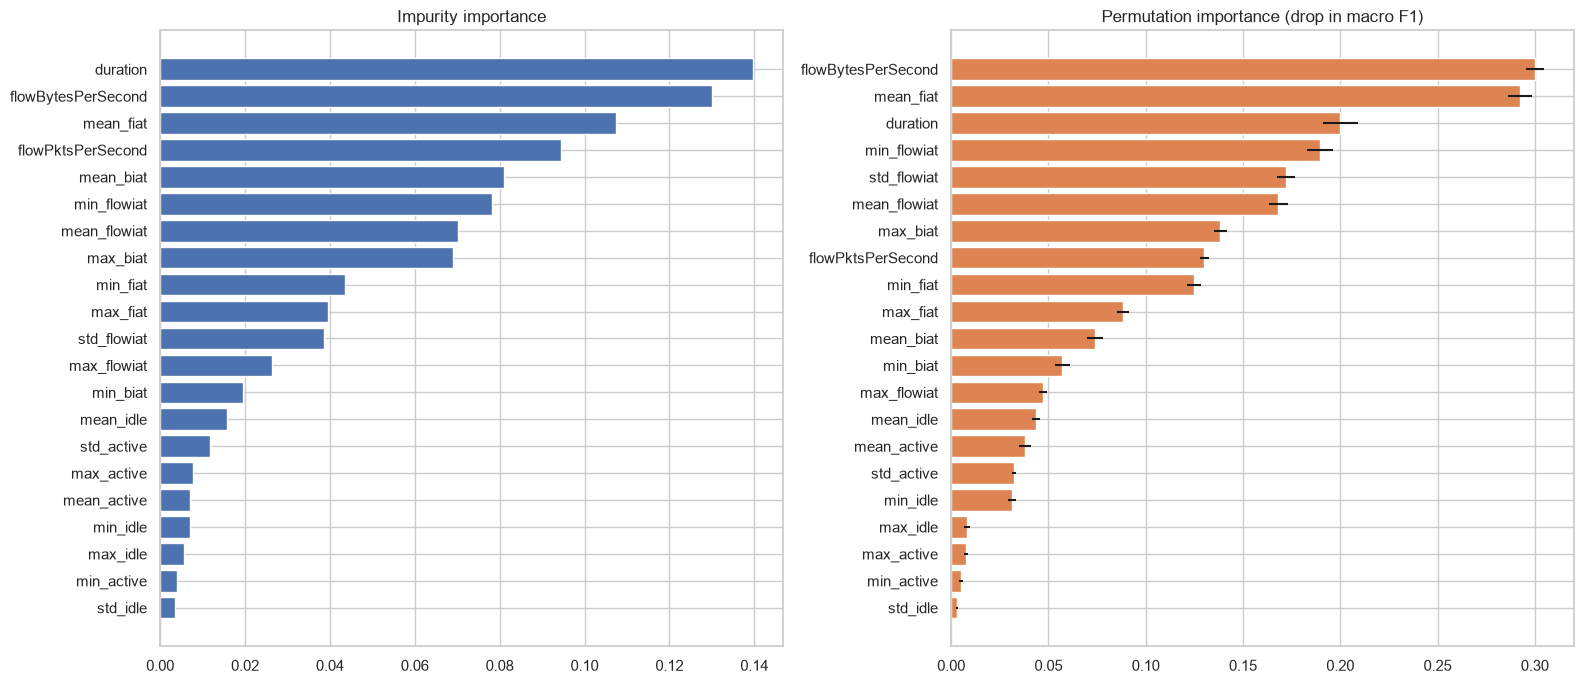

,impurity_importance,permutation_mean,permutation_std
flowBytesPerSecond,0.1300,0.3001,0.0048
mean_fiat,0.1074,0.2923,0.0061
duration,0.1398,0.2001,0.0088
min_flowiat,0.0783,0.1898,0.0067
std_flowiat,0.0386,0.1722,0.0047
mean_flowiat,0.0701,0.1681,0.0049
max_biat,0.0690,0.1384,0.0035
flowPktsPerSecond,0.0945,0.1301,0.0023
min_fiat,0.0435,0.1248,0.0038
max_fiat,0.0395,0.0882,0.0031


In [21]:
impurity_imp = pd.Series(final_model.feature_importances_, index=FEATURES, name="impurity_importance")

perm = permutation_importance(
    final_model, X_test, y_test, scoring="f1_macro",
    n_repeats=10, random_state=SEED, n_jobs=-1,
)
perm_imp = pd.DataFrame({
    "permutation_mean": perm.importances_mean,
    "permutation_std": perm.importances_std,
}, index=FEATURES)

importance_table = pd.concat([impurity_imp, perm_imp], axis=1).sort_values("permutation_mean", ascending=False)
importance_table.to_csv(TAB_DIR / "feature_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
order_imp = importance_table.sort_values("impurity_importance")
axes[0].barh(order_imp.index, order_imp["impurity_importance"], color="#4C72B0")
axes[0].set_title("Impurity importance")
order_perm = importance_table.sort_values("permutation_mean")
axes[1].barh(order_perm.index, order_perm["permutation_mean"], xerr=order_perm["permutation_std"], color="#DD8452")
axes[1].set_title("Permutation importance (drop in macro F1)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

importance_table.round(4)

## 16. Look inside the tree

The best thing about a Decision Tree is that we can **see the rules** it learned.
The full tree is too big to read, so we draw only the **top 3 levels**. Each box shows:

- the rule used to split (for example `duration <= 5000`)
- how many rows reach that box
- the class that most rows in that box belong to

We also save the full set of rules as a text file (`tree_rules.txt`).

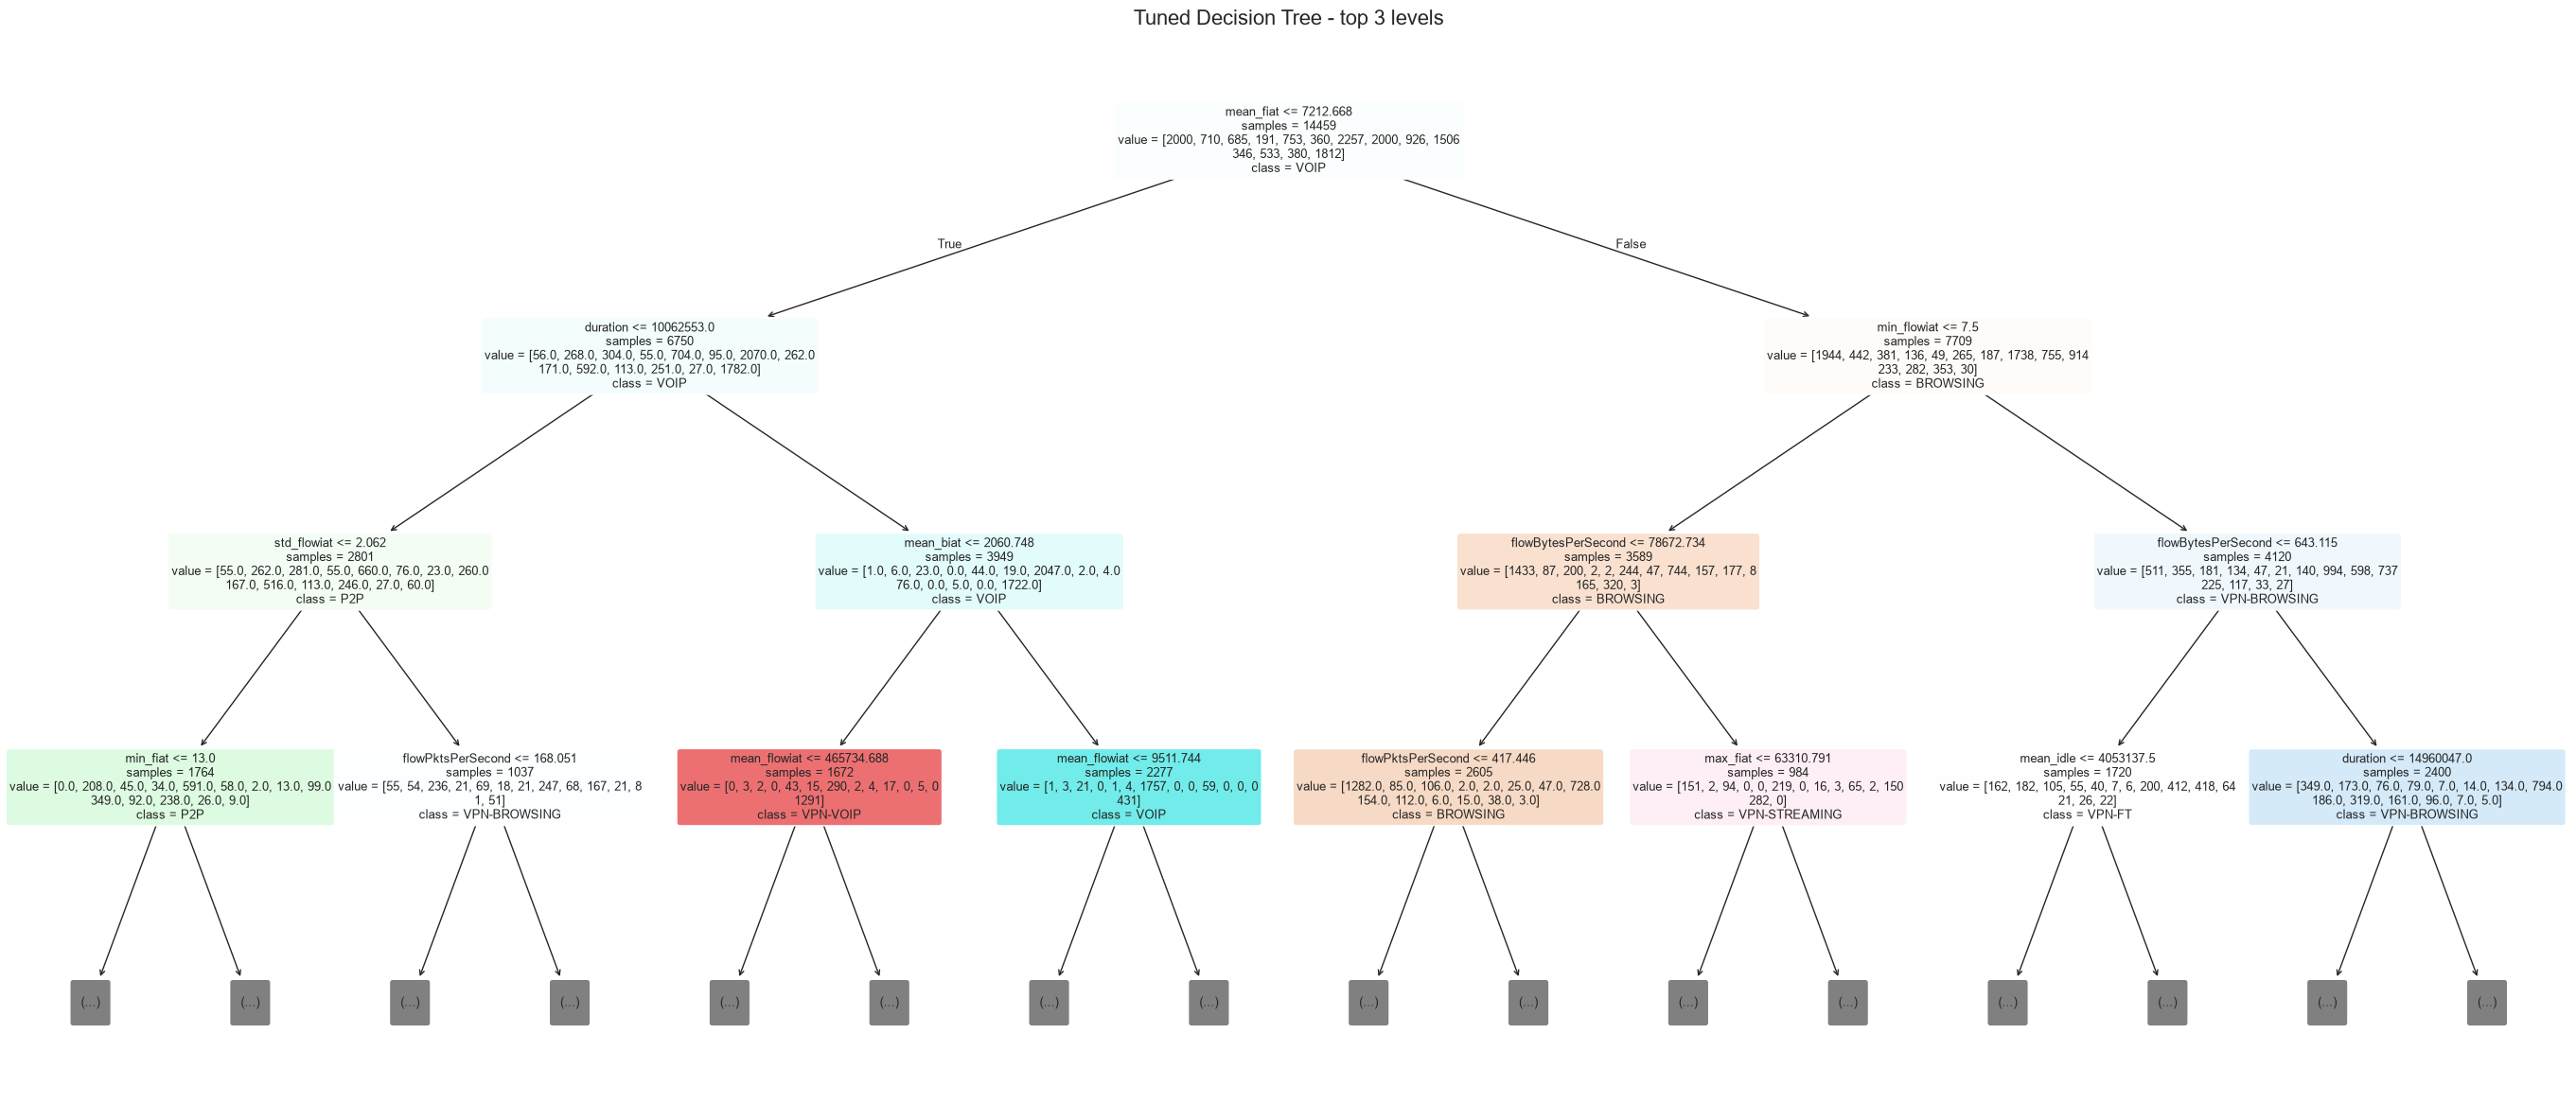

Number of lines in the rules file: 1066

|--- mean_fiat <= 7212.67
|   |--- duration <= 10062553.00
|   |   |--- std_flowiat <= 2.06
|   |   |   |--- min_fiat <= 13.00
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- min_fiat >  13.00
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- std_flowiat >  2.06
|   |   |   |--- flowPktsPerSecond <= 168.05
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- flowPktsPerSecond >  168.05
|   |   |   |   |--- truncated branch of depth 8
|   |--- duration >  10062553.00
|   |   |--- mean_biat <= 2060.75
|   |   |   |--- mean_flowiat <= 465734.69
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- mean_flowiat >  465734.69
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- mean_biat >  2060.75
|   |   |   |--- mean_flowiat <= 9511.74
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- mean_flowiat >  9511.74
|   |   |   |   |--- truncated branch of depth 6
|--- mean_f

In [22]:
fig, ax = plt.subplots(figsize=(28, 12))
plot_tree(
    final_model, max_depth=3, feature_names=FEATURES, class_names=list(final_model.classes_),
    filled=True, rounded=True, fontsize=9, impurity=False, proportion=False, ax=ax,
)
ax.set_title("Tuned Decision Tree - top 3 levels", fontsize=16)
plt.tight_layout()
plt.savefig(FIG_DIR / "tree_top_levels.png", dpi=200, bbox_inches="tight")
plt.show()

rules = export_text(final_model, feature_names=FEATURES, show_weights=False)
(OUT_DIR / "tree_rules.txt").write_text(rules)
print("Number of lines in the rules file:", len(rules.splitlines()))
print()
print(export_text(final_model, feature_names=FEATURES, max_depth=3))

## 17. Tuned model on all four time windows

The dataset comes with four time windows: 15s, 30s, 60s and 120s. The team tested Logistic Regression on
all four, so we do the same with our tuned Decision Tree. We use the same best settings found on 15s
for every window, so the comparison is fair.

  15s done  -> macro F1 = 0.7272


  30s done  -> macro F1 = 0.7368


  60s done  -> macro F1 = 0.7111
 120s done  -> macro F1 = 0.7052


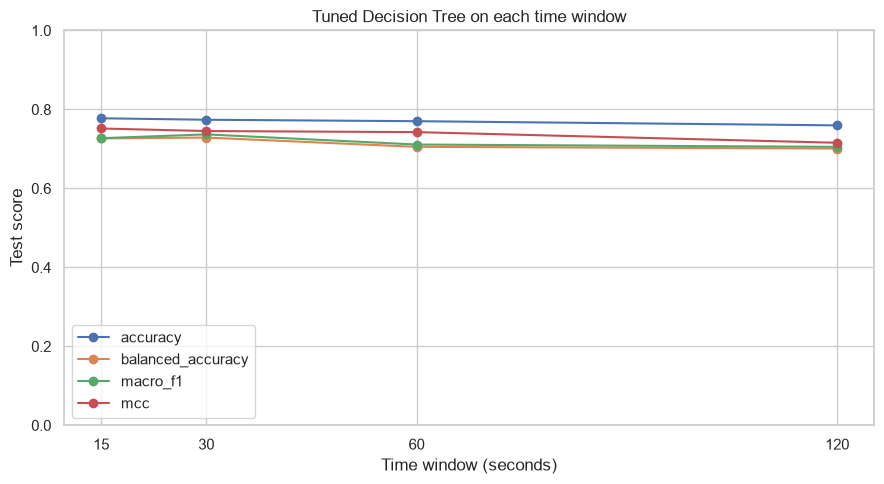

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,train_accuracy,train_rows,test_rows,tree_depth,tree_leaves
timeout,,,,,,,,,,,,
15,0.7776,0.7266,0.7321,0.7266,0.7272,0.7780,0.7517,0.8702,14459,3615,22,585
30,0.7738,0.7287,0.7518,0.7287,0.7368,0.7719,0.7452,0.8946,10910,2728,20,702
60,0.7702,0.7052,0.7210,0.7052,0.7111,0.7697,0.7425,0.8785,11783,2946,21,672
120,0.7596,0.7008,0.7194,0.7008,0.7052,0.7571,0.7155,0.9082,7671,1918,25,704


In [23]:
timeout_rows = []
for t in ALL_TIMEOUTS:
    tr, te = load_split(t)
    model_t = DecisionTreeClassifier(**best_params, random_state=SEED)
    model_t.fit(tr[FEATURES], tr[TARGET])
    scores = get_scores(te[TARGET], model_t.predict(te[FEATURES]))
    scores["train_accuracy"] = accuracy_score(tr[TARGET], model_t.predict(tr[FEATURES]))
    scores["timeout"] = t
    scores["train_rows"] = len(tr)
    scores["test_rows"] = len(te)
    scores["tree_depth"] = model_t.get_depth()
    scores["tree_leaves"] = model_t.get_n_leaves()
    timeout_rows.append(scores)
    print(f"{t:>4}s done  -> macro F1 = {scores['macro_f1']:.4f}")

timeout_table = pd.DataFrame(timeout_rows).set_index("timeout")
timeout_table.to_csv(TAB_DIR / "timeout_comparison.csv")

fig, ax = plt.subplots(figsize=(9, 5))
timeout_table[["accuracy", "balanced_accuracy", "macro_f1", "mcc"]].plot(marker="o", ax=ax)
ax.set_xticks(ALL_TIMEOUTS)
ax.set_xlabel("Time window (seconds)")
ax.set_ylabel("Test score")
ax.set_title("Tuned Decision Tree on each time window")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIG_DIR / "timeout_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

timeout_table.round(4)

## 18. Compare with the team's Logistic Regression

The team saved Logistic Regression results in `reports/results/logistic_regression_timeout_comparison.csv`.
We put them next to our Decision Tree results. Both models used the same train and test files,
so the comparison is fair.

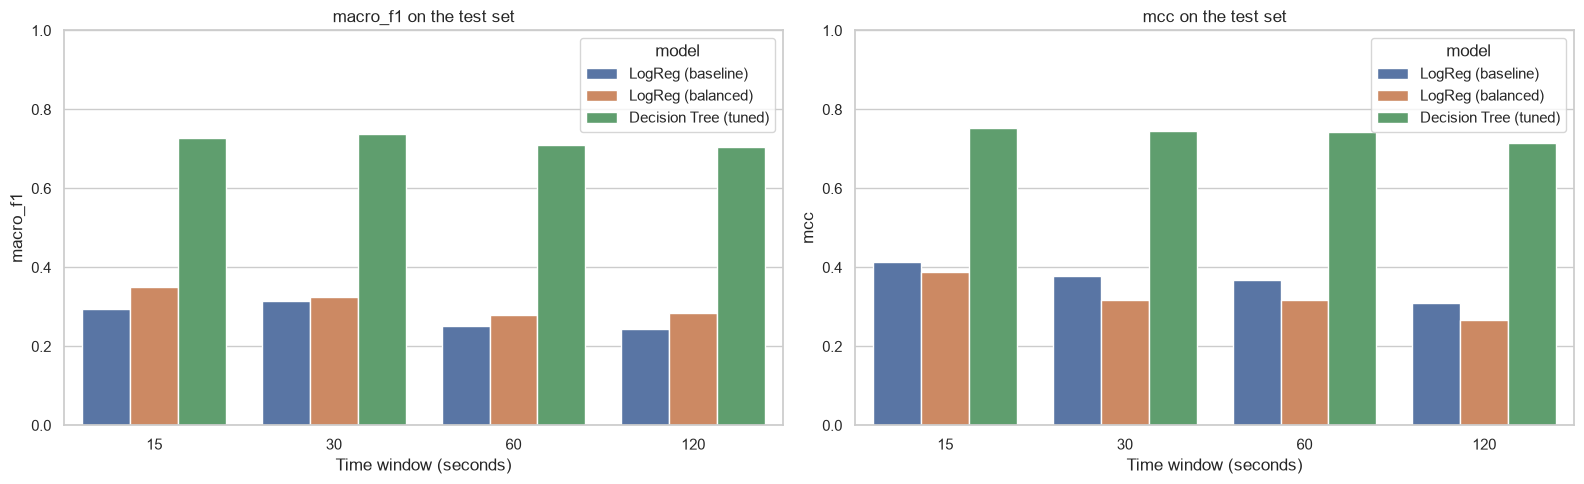

timeout,15,30,60,120
model,,,,
Decision Tree (tuned),0.7272,0.7368,0.7111,0.7052
LogReg (balanced),0.3490,0.3244,0.2796,0.2847
LogReg (baseline),0.2950,0.3135,0.2506,0.2451


In [24]:
logreg_file = PROJECT_ROOT / "reports" / "results" / "logistic_regression_timeout_comparison.csv"

if logreg_file.exists():
    logreg = pd.read_csv(logreg_file)
    rows = []
    for _, r in logreg.iterrows():
        rows.append({"model": f"LogReg ({r['experiment']})", "timeout": r["timeout"],
                     "accuracy": r["accuracy"], "macro_f1": r["macro_f1"],
                     "balanced_accuracy": r["balanced_accuracy"], "mcc": r["mcc"]})
    for t, r in timeout_table.iterrows():
        rows.append({"model": "Decision Tree (tuned)", "timeout": t,
                     "accuracy": r["accuracy"], "macro_f1": r["macro_f1"],
                     "balanced_accuracy": r["balanced_accuracy"], "mcc": r["mcc"]})
    model_compare = pd.DataFrame(rows)
    model_compare.to_csv(TAB_DIR / "model_comparison_with_logreg.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric in zip(axes, ["macro_f1", "mcc"]):
        sns.barplot(data=model_compare, x="timeout", y=metric, hue="model", ax=ax)
        ax.set_title(f"{metric} on the test set")
        ax.set_xlabel("Time window (seconds)")
        ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "model_comparison_with_logreg.png", dpi=200, bbox_inches="tight")
    plt.show()

    display(model_compare.pivot(index="model", columns="timeout", values="macro_f1").round(4))
else:
    print("Logistic Regression results file not found, skipping this step.")

## 19. Save the final model

We save the trained model with `joblib`, plus a small JSON file with the model details.
You can load the model later like this:

```python
model = joblib.load("reports/results/decision_tree/model/decision_tree_14class_15s.joblib")
model.predict(new_data[FEATURES])
```

Note: the project `.gitignore` ignores `*.joblib` files, so the model file will not be pushed to git.
All other results (tables and figures) will be pushed.

In [25]:
model_path = MODEL_DIR / f"decision_tree_{TASK}_{TIMEOUT}s.joblib"
joblib.dump(final_model, model_path)

model_info = {
    "model": "DecisionTreeClassifier",
    "task": TASK,
    "timeout_seconds": TIMEOUT,
    "features": FEATURES,
    "classes": CLASSES,
    "best_params": {k: to_json_value(v) for k, v in best_params.items()},
    "tree_depth": int(final_model.get_depth()),
    "tree_leaves": int(final_model.get_n_leaves()),
    "cv_folds": N_FOLDS,
    "cv_macro_f1_mean": float(tuned_cv_table.loc["macro_f1", "val_mean"]),
    "cv_macro_f1_std": float(tuned_cv_table.loc["macro_f1", "val_std"]),
    "test_scores": {k: float(test_scores.loc[k, "tuned_test"]) for k in get_scores(y_test, y_test_pred)},
}
with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

loaded = joblib.load(model_path)
print("Model saved to:", model_path)
print("Loaded model gives the same test macro F1:",
      round(f1_score(y_test, loaded.predict(X_test), average="macro"), 4))

Model saved to: C:\Users\suner\Downloads\ml\ML-Traffic-Classification-main\reports\results\decision_tree\model\decision_tree_14class_15s.joblib
Loaded model gives the same test macro F1: 0.7272


## 20. Final summary

The cell below prints the main numbers and lists every file saved in the results folder.

In [26]:
print("=" * 60)
print(f"DECISION TREE - {TASK} - {TIMEOUT}s")
print("=" * 60)
print("Best settings:", best_params)
print(f"Tree depth / leaves: {final_model.get_depth()} / {final_model.get_n_leaves()}")
print()
print(f"CV macro F1     : {tuned_cv_table.loc['macro_f1', 'val_mean']:.4f} +/- {tuned_cv_table.loc['macro_f1', 'val_std']:.4f}")
print(f"Test accuracy   : {test_scores.loc['accuracy', 'tuned_test']:.4f}")
print(f"Test bal. acc.  : {test_scores.loc['balanced_accuracy', 'tuned_test']:.4f}")
print(f"Test macro F1   : {test_scores.loc['macro_f1', 'tuned_test']:.4f}")
print(f"Test MCC        : {test_scores.loc['mcc', 'tuned_test']:.4f}")
print()
print("Saved files:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(PROJECT_ROOT))

DECISION TREE - 14class - 15s
Best settings: {'splitter': 'best', 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 25, 'criterion': 'gini', 'class_weight': None, 'ccp_alpha': 0.0002}
Tree depth / leaves: 22 / 585

CV macro F1     : 0.7486 +/- 0.0082
Test accuracy   : 0.7776
Test bal. acc.  : 0.7266
Test macro F1   : 0.7272
Test MCC        : 0.7517

Saved files:
   reports\results\decision_tree\best_params.json
   reports\results\decision_tree\figures\baseline_vs_tuned_cv.png
   reports\results\decision_tree\figures\class_counts.png
   reports\results\decision_tree\figures\confusion_matrix.png
   reports\results\decision_tree\figures\cv_folds.png
   reports\results\decision_tree\figures\feature_importance.png
   reports\results\decision_tree\figures\learning_curve.png
   reports\results\decision_tree\figures\model_comparison_with_logreg.png
   reports\results\decision_tree\figures\per_class_scores.png
   reports\results\decision_tree\figures\timeout_compa

## 21. Conclusion

**What we did**

- Trained a Decision Tree to classify 14 types of network traffic from 21 time-based flow features.
- Used group-aware 5-fold cross validation, so the same flow never appears in both the training and validation part.
- Tuned the model with randomized search (150 settings) and picked the best setting by macro F1.
- Checked the model with learning curves and three validation curves.
- Tested the final model once on the hold-out test set.
- Looked inside the tree to see the rules it learned.

**How to read the results**

- Look at `tables/test_scores.csv` for the final scores, and compare tuned vs baseline.
- The **baseline tree overfits** (train score near 1.0). Tuning makes the tree smaller and closes part of this gap.
- **Important note about tuned vs baseline on the test set:** in our run the tuned tree got a slightly *lower* test macro F1
  (about 0.73) than the default tree (about 0.75). This is normal and it is not a mistake. We picked the settings using
  **cross validation only** (the correct way), and in cross validation the tuned tree was a little better (0.749 vs 0.743).
  The tuned tree is also about **4 times smaller** (585 leaves vs 2259 leaves) and overfits much less
  (train macro F1 0.86 vs 0.99). A smaller tree is easier to explain and more reliable on new data, so we keep the tuned tree
  as our final model. The small difference on the test set shows that a single decision tree has high variance:
  small changes in data or settings can move the score by a few points.
- The **learning curve** shows if more data would help (validation line still going up) and how big the overfitting gap is.
- The **validation curves** show how tree size (depth, leaf size, pruning) changes overfitting and underfitting.
- The **confusion matrix** shows which classes are mixed up. Normal and VPN versions of the same app type
  (for example `CHAT` and `VPN-CHAT`) and similar apps (for example `BROWSING` and `CHAT`) are usually the hardest.
- The **timeout comparison** shows which time window works best for this model.
- The **comparison with Logistic Regression** shows how much a non-linear model improves on the team's linear baseline.

All tables, figures, the tree rules and the saved model are in `reports/results/decision_tree/`.